            Penjualan  Moving_Average
2026-01-01         10             NaN
2026-01-02         20       20.000000
2026-01-03         30       21.666667
2026-01-04         15       23.333333
2026-01-05         25       26.666667
2026-01-06         40       33.333333
2026-01-07         35       41.666667
2026-01-08         50       43.333333
2026-01-09         45       51.666667
2026-01-10         60             NaN


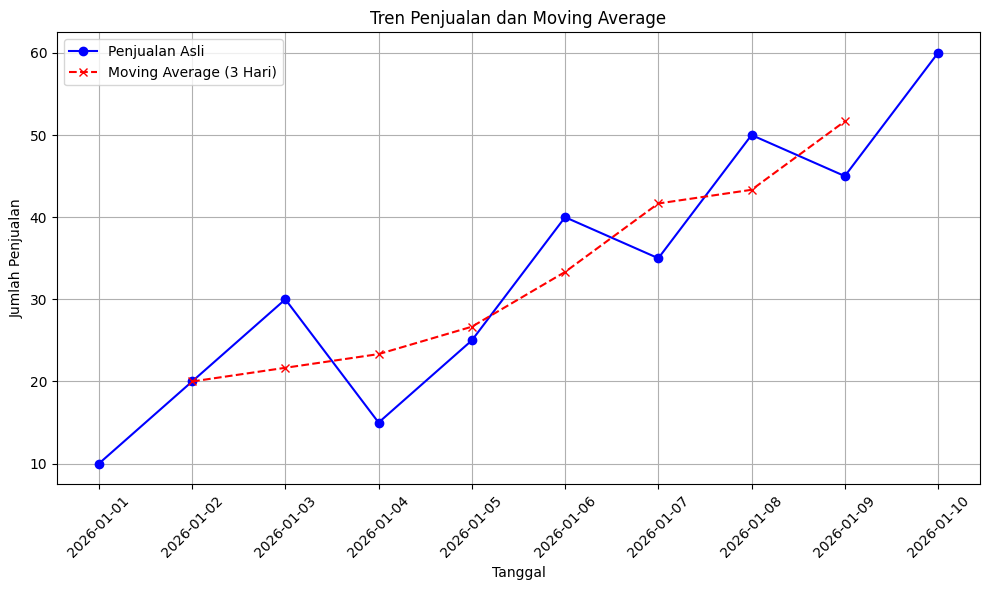

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

hari = pd.date_range('2026-01-01', periods=10)
penjualan = [10, 20, 30, 15, 25, 40, 35, 50, 45, 60]
df_tren = pd.DataFrame({'Penjualan': penjualan}, index=hari)

df_tren['Moving_Average'] = df_tren['Penjualan'].rolling(
    window=3,
    center=True
).mean()

print(df_tren)

plt.figure(figsize=(10, 6))
plt.plot(df_tren.index, df_tren['Penjualan'], marker='o', label='Penjualan Asli', color='blue')
plt.plot(df_tren.index, df_tren['Moving_Average'], marker='x', linestyle='--', label='Moving Average (3 Hari)', color='red')

plt.title('Tren Penjualan dan Moving Average')
plt.xlabel('Tanggal')
plt.ylabel('Jumlah Penjualan')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


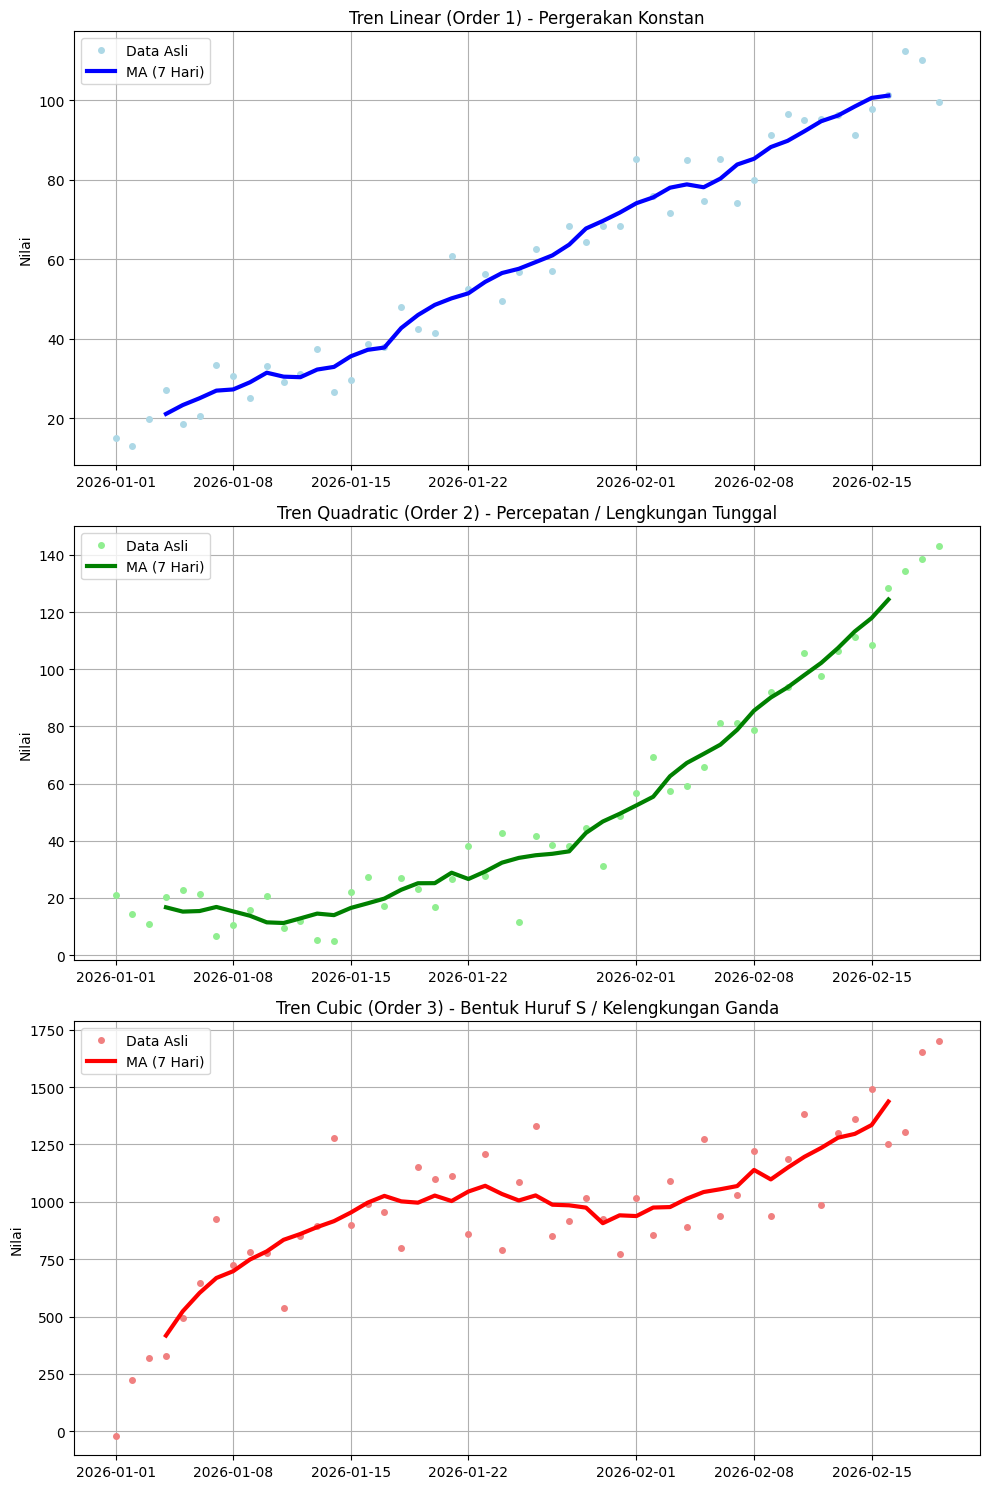

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Data Simulasi (50 Hari)
np.random.seed(42)
hari = pd.date_range('2026-01-01', periods=50)
t = np.arange(1, 51)

# Persamaan Linear 
linear_data = 2 * t + 10 + np.random.normal(0, 6, 50)

# Persamaan Quadratic
quad_data = 0.08 * (t**2) - 1.5 * t + 20 + np.random.normal(0, 8, 50)

# Persamaan Cubic
t_shifted = t - 25 
cubic_data = 0.05 * (t_shifted**3) - 0.2 * (t_shifted**2) + np.random.normal(0, 150, 50) + 1000

# Perhitungan Moving Average (Window = 7 Hari)
df = pd.DataFrame({'Linear': linear_data, 'Quadratic': quad_data, 'Cubic': cubic_data}, index=hari)
df['MA_Linear'] = df['Linear'].rolling(window=7, center=True).mean()
df['MA_Quadratic'] = df['Quadratic'].rolling(window=7, center=True).mean()
df['MA_Cubic'] = df['Cubic'].rolling(window=7, center=True).mean()

# Visualisasi
fig, axes = plt.subplots(3, 1, figsize=(10, 15))

# Konfigurasi Grafik Linear
axes[0].plot(df.index, df['Linear'], marker='o', markersize=4, linestyle='', color='lightblue', label='Data Asli')
axes[0].plot(df.index, df['MA_Linear'], color='blue', linewidth=3, label='MA (7 Hari)')
axes[0].set_title('Tren Linear (Order 1) - Pergerakan Konstan')

# Konfigurasi Grafik Quadratic
axes[1].plot(df.index, df['Quadratic'], marker='o', markersize=4, linestyle='', color='lightgreen', label='Data Asli')
axes[1].plot(df.index, df['MA_Quadratic'], color='green', linewidth=3, label='MA (7 Hari)')
axes[1].set_title('Tren Quadratic (Order 2) - Percepatan / Lengkungan Tunggal')

# Konfigurasi Grafik Cubic
axes[2].plot(df.index, df['Cubic'], marker='o', markersize=4, linestyle='', color='lightcoral', label='Data Asli')
axes[2].plot(df.index, df['MA_Cubic'], color='red', linewidth=3, label='MA (7 Hari)')
axes[2].set_title('Tren Cubic (Order 3) - Bentuk Huruf S / Kelengkungan Ganda')

for ax in axes:
    ax.tick_params(axis='x', rotation=0)
    ax.grid(True)
    ax.legend()
    ax.set_ylabel('Nilai')

plt.tight_layout()
plt.show()

In [ ]:
from statsmodels.tsa.deterministic import DeterministicProcess

dp = DeterministicProcess(
    index=df.index, 
    constant=True,       
    order=2,             
    drop=True            
)

X_tren = dp.in_sample()

print("=== Fitur Tren Kuadratik (Order 2) ===")
print(X_tren.head())

=== Fitur Tren Kuadratik (Order 2) ===
            const  trend  trend_squared
2026-01-01    1.0    1.0            1.0
2026-01-02    1.0    2.0            4.0
2026-01-03    1.0    3.0            9.0
2026-01-04    1.0    4.0           16.0
2026-01-05    1.0    5.0           25.0
=== Fitur Kalender ===
            Bulan  Tanggal  Hari_Ke  Akhir_Pekan
2026-03-14      3       14        5            1
2026-03-15      3       15        6            1
2026-03-16      3       16        0            0
2026-03-17      3       17        1            0


In [ ]:
waktu = pd.date_range(start='2026-03-14', periods=4, freq='D')
df_kalender = pd.DataFrame(index=waktu)

# 1. Ekstraksi Fitur Numerik
df_kalender['Bulan'] = df_kalender.index.month
df_kalender['Tanggal'] = df_kalender.index.day
df_kalender['Hari_Ke'] = df_kalender.index.dayofweek

# 2. Ekstraksi Fitur Biner (Kondisional)
# Jika Hari_Ke adalah 5 (Sabtu) atau 6 (Minggu), berikan nilai 1, sisanya 0
df_kalender['Akhir_Pekan'] = np.where(df_kalender['Hari_Ke'] >= 5, 1, 0)

print("=== Fitur Kalender ===")
print(df_kalender)

In [4]:
import pandas as pd
import numpy as np

data_mentah = {
    'Tanggal_Teks': ['2026-03-01', '02/03/2026', 'March 3, 2026', '2026-03-05', '2026-03-06'], # Tgl 4 Hilang
    'Penjualan': [150, 160, 155, 170, 165]
}
df = pd.DataFrame(data_mentah)

print("=== 1. Tipe Data Awal ===")
print(df.dtypes)
df.head()

=== 1. Tipe Data Awal ===
Tanggal_Teks    object
Penjualan        int64
dtype: object


,Tanggal_Teks,Penjualan
0,2026-03-01,150
1,02/03/2026,160
2,"March 3, 2026",155
3,2026-03-05,170
4,2026-03-06,165


In [5]:
# pd.to_datetime dapat membaca berbagai format teks menjadi format baku YYYY-MM-DD
df['Waktu_Baku'] = pd.to_datetime(df['Tanggal_Teks'], format='mixed', dayfirst=True)

# Pindahkan kolom waktu menjadi urutan baris utama (index), lalu buang kolom teks aslinya
df = df.set_index('Waktu_Baku')
df = df.drop(columns=['Tanggal_Teks'])

print("\n=== 2. Data Setelah Konversi dan Set Index ===")
print(df)
print("Tipe Indeks saat ini:", type(df.index))


=== 2. Data Setelah Konversi dan Set Index ===
            Penjualan
Waktu_Baku           
2026-03-01        150
2026-03-02        160
2026-03-03        155
2026-03-05        170
2026-03-06        165
Tipe Indeks saat ini: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>


In [6]:
# Cek frekuensi saat ini, jika 'None' = sistem belum yakin polanya akibat tanggal yang hilang
print(f"\nFrekuensi awal: {df.index.freq}") 

# Atur frekuensi menjadi Harian ('D') menggunakan .asfreq()
df = df.asfreq('D')

print("\n=== 3. Data Setelah Penetapan Frekuensi ('D') ===")
print(f"\nFrekuensi akhir: {df.index.freq}") 
print(df)
# Perhatikan bahwa baris '2026-03-04' kini muncul dengan nilai NaN (Kosong)


Frekuensi awal: None

=== 3. Data Setelah Penetapan Frekuensi ('D') ===

Frekuensi akhir: <Day>
            Penjualan
Waktu_Baku           
2026-03-01      150.0
2026-03-02      160.0
2026-03-03      155.0
2026-03-04        NaN
2026-03-05      170.0
2026-03-06      165.0


In [7]:
df['Penjualan'] = df['Penjualan'].ffill() 

print("\n=== 4. Data Final Siap Masuk Algoritma ===")
print(df)
print(f"Frekuensi Final: {df.index.freq}") # Output: <Day>


=== 4. Data Final Siap Masuk Algoritma ===
            Penjualan
Waktu_Baku           
2026-03-01      150.0
2026-03-02      160.0
2026-03-03      155.0
2026-03-04      155.0
2026-03-05      170.0
2026-03-06      165.0
Frekuensi Final: <Day>


In [ ]:
from statsmodels.tsa.deterministic import DeterministicProcess

# Data Simulasi (50 Hari)
np.random.seed(42)
hari = pd.date_range('2026-01-01', periods=50)
t = np.arange(1, 51)

# Persamaan Linear 
linear_data = 2 * t + 10 + np.random.normal(0, 6, 50)

df = pd.DataFrame({'Linear': linear_data}, index=hari)

# 1. Ekstraksi In-Sample (Untuk Pelatihan Historis)
dp = DeterministicProcess(
    index=df.index,
    constant=True,
    order=1,
    drop=True
)
X_tren_historis = dp.in_sample()

# 2. Ekstraksi Out-of-Sample (Untuk Masa Depan)
horizon_masa_depan = 24 # Ingin meramal 24 langkah ke depan
X_tren_masa_depan = dp.out_of_sample(steps=horizon_masa_depan)

# X_tren_masa_depan langsung berisi kelanjutan angka tren yang siap di-predict()

print("Fitur Tren Historis (In-Sample):")
print(X_tren_historis.head())
print("\nFitur Tren Masa Depan (Out-of-Sample):")
print(X_tren_masa_depan.head())

Fitur Tren Historis (In-Sample):
            const  trend
2026-01-01    1.0    1.0
2026-01-02    1.0    2.0
2026-01-03    1.0    3.0
2026-01-04    1.0    4.0
2026-01-05    1.0    5.0

Fitur Tren Masa Depan (Out-of-Sample):
            const  trend
2026-02-20    1.0   51.0
2026-02-21    1.0   52.0
2026-02-22    1.0   53.0
2026-02-23    1.0   54.0
2026-02-24    1.0   55.0


=== Blueprint Fitur Dummy Masa Depan (Sebelum Dilooping) ===
            trend  Hari_Monday  Hari_Saturday  Hari_Sunday  Hari_Thursday  \
2024-01-31   31.0            0              0            0              0   
2024-02-01   32.0            0              0            0              1   
2024-02-02   33.0            0              0            0              0   
2024-02-03   34.0            0              1            0              0   
2024-02-04   35.0            0              0            1              0   

            Hari_Tuesday  Hari_Wednesday  
2024-01-31             0               1  
2024-02-01             0               0  
2024-02-02             0               0  
2024-02-03             0               0  
2024-02-04             0               0  


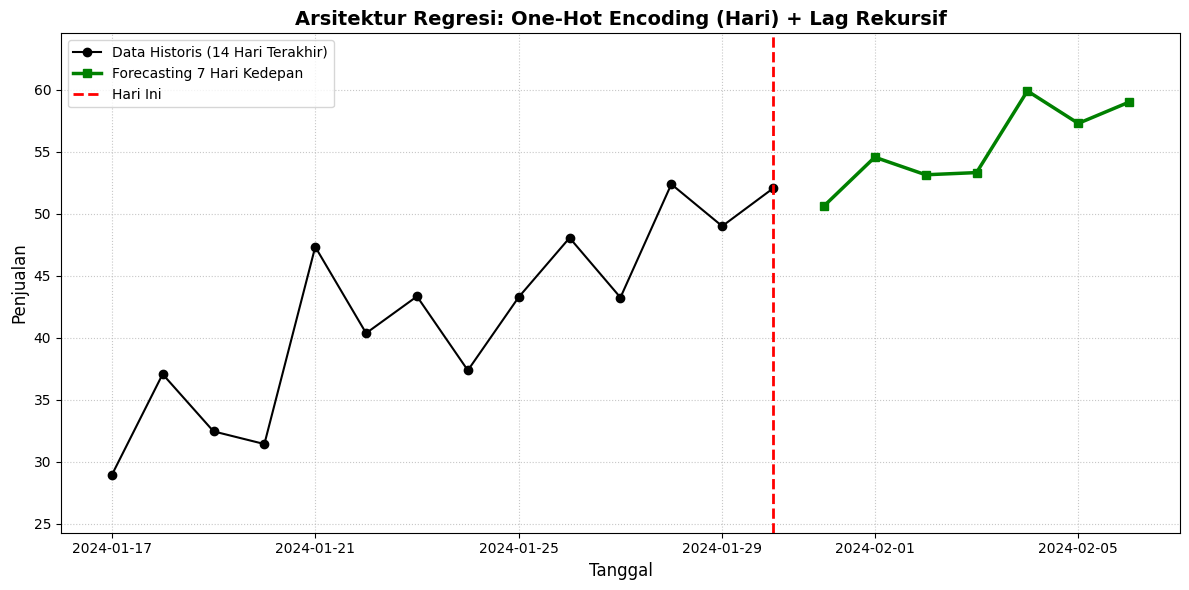

In [9]:
# ==============================================================================
# FASE 1: PERSIAPAN DATA HISTORIS (30 Hari)
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from statsmodels.tsa.deterministic import DeterministicProcess

np.random.seed(42)
tanggal_historis = pd.date_range('2024-01-01', periods=30, freq='D')

tren_asli = 10 + (np.arange(30) * 1.5)
penjualan = tren_asli + np.random.normal(0, 5, 30)

df = pd.DataFrame({'Penjualan': penjualan}, index=tanggal_historis)

df['Lag_1'] = df['Penjualan'].shift(1)

df['Nama_Hari'] = df.index.day_name()
dummy_historis = pd.get_dummies(df['Nama_Hari'], prefix='Hari', drop_first=True, dtype=int)

dp = DeterministicProcess(index=df.index, constant=True, order=1, drop=True)
X_tren_historis = dp.in_sample()
df_lengkap = pd.concat([df, X_tren_historis, dummy_historis], axis=1)
df_bersih = df_lengkap.dropna()

# ==============================================================================
# FASE 2: PELATIHAN MODEL (MACHINE LEARNING)
# ==============================================================================
kolom_dummy = list(dummy_historis.columns)

fitur_kunci = ['const', 'trend', 'Lag_1'] + kolom_dummy

X_train = df_bersih[fitur_kunci]
y_train = df_bersih['Penjualan']

model = LinearRegression(fit_intercept=False)
model.fit(X_train, y_train)

# ==============================================================================
# FASE 3: MEMBANGUN BLUEPRINT MASA DEPAN 
# ==============================================================================
langkah_depan = 7 

df_masa_depan = dp.out_of_sample(steps=langkah_depan)

df_masa_depan['Nama_Hari'] = df_masa_depan.index.day_name()
dummy_masa_depan = pd.get_dummies(df_masa_depan['Nama_Hari'], prefix='Hari', dtype=int)

dummy_masa_depan = dummy_masa_depan.reindex(columns=kolom_dummy, fill_value=0)

df_masa_depan = pd.concat([df_masa_depan, dummy_masa_depan], axis=1)

print("=== Blueprint Fitur Dummy Masa Depan (Sebelum Dilooping) ===")
print(df_masa_depan[['trend'] + kolom_dummy].head())

# ==============================================================================
# FASE 4: LOOPING REKURSIF
# ==============================================================================
nilai_lag_terakhir = df_bersih['Penjualan'].iloc[-1]
prediksi_penjualan = []

for i in range(langkah_depan):
    baris_hari_ini = df_masa_depan.iloc[[i]].copy()
    baris_hari_ini['Lag_1'] = nilai_lag_terakhir
    
    X_prediksi = baris_hari_ini[fitur_kunci]
    
    prediksi_hari_ini = model.predict(X_prediksi)[0]
    prediksi_penjualan.append(prediksi_hari_ini)
    nilai_lag_terakhir = prediksi_hari_ini

df_masa_depan['Prediksi_Penjualan'] = prediksi_penjualan

# ==============================================================================
# FASE 5: VISUALISASI HASIL
# ==============================================================================
plt.figure(figsize=(12, 6))

plt.plot(df_bersih.index[-14:], df_bersih['Penjualan'].iloc[-14:], marker='o', color='black', label='Data Historis (14 Hari Terakhir)')
plt.plot(df_masa_depan.index, df_masa_depan['Prediksi_Penjualan'], marker='s', color='green', linewidth=2.5, label='Forecasting 7 Hari Kedepan')

plt.axvline(x=df_bersih.index[-1], color='red', linestyle='--', linewidth=2, label='Hari Ini')

plt.title('Arsitektur Regresi: One-Hot Encoding (Hari) + Lag Rekursif', fontsize=14, fontweight='bold')
plt.xlabel('Tanggal', fontsize=12)
plt.ylabel('Penjualan', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, linestyle=':', alpha=0.7)
plt.margins(y=0.15)
plt.tight_layout()

plt.show()

Assignment

=== Data Info Awal ===
Shape: (114, 4)
             meantemp   humidity  wind_speed  meanpressure
date                                                      
2017-01-01  15.913043  85.869565    2.743478     59.000000
2017-01-02  18.500000  77.222222    2.894444   1018.277778
2017-01-03  17.111111  81.888889    4.016667   1018.333333

=== Data Splitting ===
Total data bersih: 113
Training data: 90 (79.6%)
Testing data: 23 (20.4%)

=== Model Linear Regression ===
Intercept (const) : 1.6614
Coefficient Trend : 0.0302
Coefficient Lag_1 : 0.8349

Memulai Looping Prediksi pada Data Test...

=== Tabel Perbandingan Aktual vs Prediksi (10 Terakhir) ===
               Aktual  Prediksi  Error  Abs_Error
date                                             
2017-04-15  31.222222     29.98   1.24       1.24
2017-04-16  31.000000     30.84   0.16       0.16
2017-04-17  32.555556     30.81   1.75       1.75
2017-04-18  34.000000     30.72   3.28       3.28
2017-04-19  33.500000     31.27   2.23       2.23

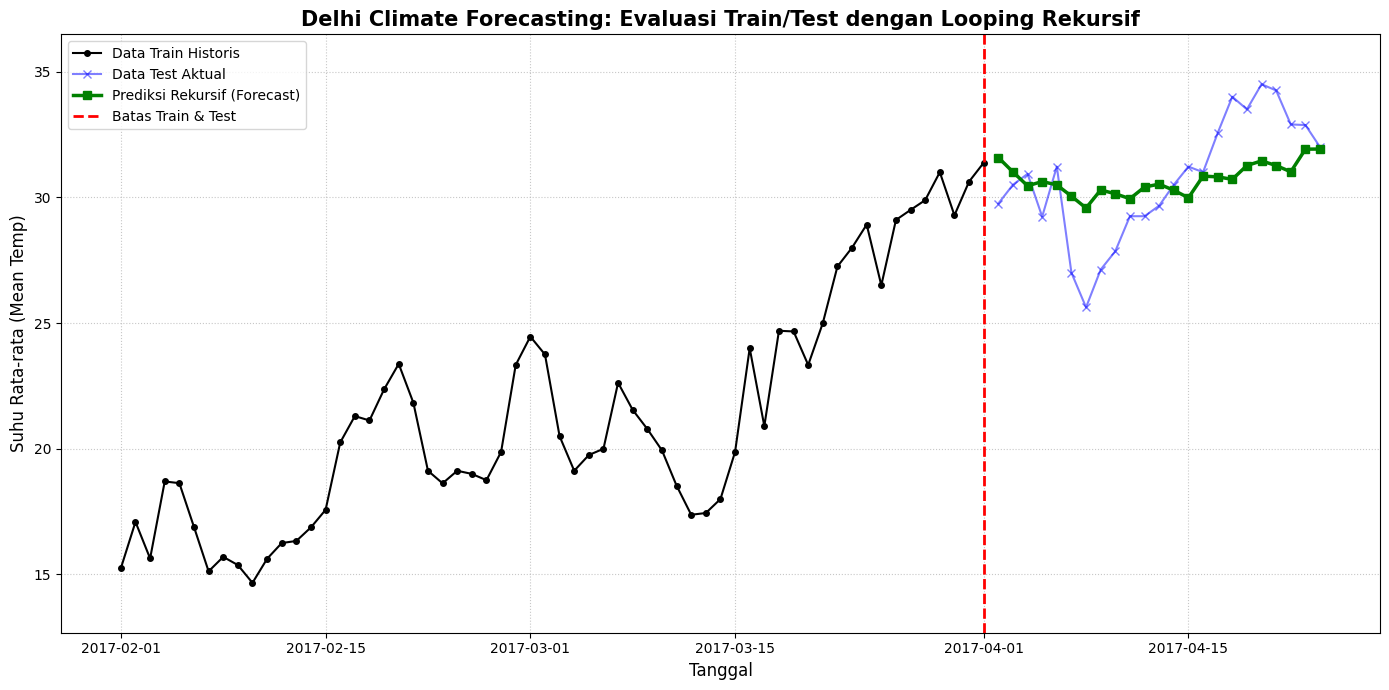

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split
from statsmodels.tsa.deterministic import DeterministicProcess
import warnings
warnings.filterwarnings('ignore')

# ==============================================================================
# FASE 1: PERSIAPAN DATA & FEATURE ENGINEERING
# ==============================================================================
# 1. Load dataset & set index
df = pd.read_csv('DailyDelhiClimateTest.csv')
df['date'] = pd.to_datetime(df['date']).dt.normalize()
df.set_index('date', inplace=True)
df.sort_index(inplace=True)

# Memastikan frekuensi index sempurna (Harian). Isi jika ada tanggal bolong.
df = df.resample('D').ffill()

print("=== Data Info Awal ===")
print(f"Shape: {df.shape}")
print(df.head(3))

# 2. Ekstraksi Fitur Dinamis (Lag)
df['Lag_1'] = df['meantemp'].shift(1)

# 3. Ekstraksi Fitur Kalender (One-Hot Encoding Hari)
df['Nama_Hari'] = df.index.day_name()
dummy_historis = pd.get_dummies(df['Nama_Hari'], prefix='Hari', drop_first=True, dtype=int)
kolom_dummy = list(dummy_historis.columns)

# 4. Ekstraksi Fitur Tren dengan statsmodels
dp = DeterministicProcess(index=df.index, constant=True, order=1, drop=True)
X_tren_historis = dp.in_sample()

# Gabungkan seluruh fitur
df_lengkap = pd.concat([df, X_tren_historis, dummy_historis], axis=1)

# Buang baris pertama yang kosong karena Lag_1
df_bersih = df_lengkap.dropna()

# ==============================================================================
# FASE 2: DATA SPLITTING (TRAIN & TEST)
# ==============================================================================
# Susun urutan fitur (Pastikan sesuai)
fitur_kunci = ['const', 'trend', 'Lag_1'] + kolom_dummy

X = df_bersih[fitur_kunci]
y = df_bersih['meantemp']

# Split data: 80% Train, 20% Test (shuffle=False WAJIB untuk Time Series)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

print("\n=== Data Splitting ===")
print(f"Total data bersih: {len(df_bersih)}")
print(f"Training data: {len(X_train)} ({len(X_train)/len(df_bersih)*100:.1f}%)")
print(f"Testing data: {len(X_test)} ({len(X_test)/len(df_bersih)*100:.1f}%)")

# ==============================================================================
# FASE 3: PELATIHAN MODEL (HANYA MENGGUNAKAN DATA TRAIN)
# ==============================================================================
# Matikan intercept karena 'const' sudah ada dari DeterministicProcess
model = LinearRegression(fit_intercept=False)
model.fit(X_train, y_train)

print("\n=== Model Linear Regression ===")
print(f"Intercept (const) : {model.coef_[0]:.4f}")
print(f"Coefficient Trend : {model.coef_[1]:.4f}")
print(f"Coefficient Lag_1 : {model.coef_[2]:.4f}")

# ==============================================================================
# FASE 4: LOOPING REKURSIF PADA DATA TEST (TRUE FORECASTING)
# ==============================================================================
# Tangkap memori suhu hari TERAKHIR dari data TRAINING
nilai_lag_terakhir = y_train.iloc[-1]
prediksi_suhu = []

# Menggunakan X_test sebagai 'Blueprint' karena sudah berisi Tren dan Hari dummy
X_test_rekursif = X_test.copy()

print("\nMemulai Looping Prediksi pada Data Test...")
for i in range(len(X_test_rekursif)):
    # Ambil baris ke-i dari Data Test
    baris_hari_ini = X_test_rekursif.iloc[[i]].copy()
    
    # SUNTIKKAN Lag dinamis (Bukan dari data asli, tapi dari memori)
    baris_hari_ini['Lag_1'] = nilai_lag_terakhir
    
    # Eksekusi Prediksi
    X_prediksi = baris_hari_ini[fitur_kunci]
    prediksi_hari_ini = model.predict(X_prediksi)[0]
    prediksi_suhu.append(prediksi_hari_ini)
    
    # Update memori: Tebakan hari ini menjadi Lag_1 untuk putaran besok
    nilai_lag_terakhir = prediksi_hari_ini

# Simpan hasil rekursif
X_test_rekursif['Prediksi_meantemp'] = prediksi_suhu

# ==============================================================================
# FASE 5: EVALUASI & VISUALISASI
# ==============================================================================
y_pred = X_test_rekursif['Prediksi_meantemp']

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

# Membuat Tabel Perbandingan
hasil_df = pd.DataFrame({
    'Aktual': y_test.values,
    'Prediksi': np.round(y_pred.values, 2)
}, index=y_test.index)

hasil_df['Error'] = np.round(hasil_df['Aktual'] - hasil_df['Prediksi'], 2)
hasil_df['Abs_Error'] = np.round(np.abs(hasil_df['Error']), 2)

print("\n=== Tabel Perbandingan Aktual vs Prediksi (10 Terakhir) ===")
print(hasil_df.tail(10))
print("\n" + "="*50)
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print("="*50)

# ----------------- VISUALISASI -----------------
plt.figure(figsize=(14, 7))

# Plot Data Train (Tampilkan 60 hari terakhir saja agar tidak terlalu rapat)
plt.plot(y_train.index[-60:], y_train.iloc[-60:], marker='o', color='black', markersize=4, label='Data Train Historis')

# Plot Data Test Aktual vs Prediksi
plt.plot(y_test.index, y_test, marker='x', color='blue', alpha=0.5, label='Data Test Aktual')
plt.plot(y_test.index, y_pred, marker='s', color='green', linewidth=2.5, label='Prediksi Rekursif (Forecast)')

plt.axvline(x=y_train.index[-1], color='red', linestyle='--', linewidth=2, label='Batas Train & Test')

plt.title('Delhi Climate Forecasting: Evaluasi Train/Test dengan Looping Rekursif', fontsize=15, fontweight='bold')
plt.xlabel('Tanggal', fontsize=12)
plt.ylabel('Suhu Rata-rata (Mean Temp)', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, linestyle=':', alpha=0.7)
plt.margins(y=0.1)
plt.tight_layout()

plt.show()

Forecasting Full

=== Model Berhasil Dilatih (100% Data) ===

=== Hasil Forecasting 14 Hari Ke Depan ===
            Prediksi_meantemp
2017-04-25              32.18
2017-04-26              32.54
2017-04-27              32.94
2017-04-28              32.60
2017-04-29              32.30
2017-04-30              33.02
2017-05-01              33.20
2017-05-02              33.40
2017-05-03              33.77
2017-05-04              34.19
2017-05-05              33.85
2017-05-06              33.55
2017-05-07              34.28
2017-05-08              34.47


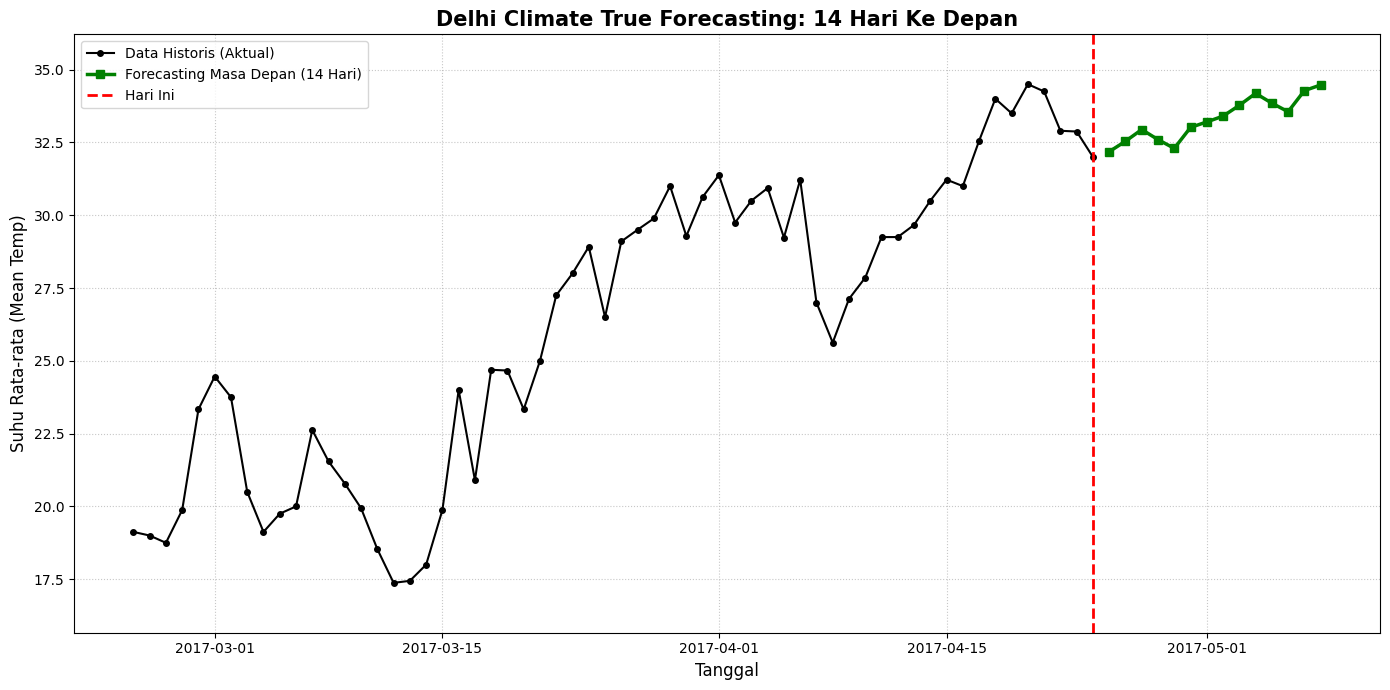

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from statsmodels.tsa.deterministic import DeterministicProcess
import warnings
warnings.filterwarnings('ignore')

# ==============================================================================
# FASE 1: PERSIAPAN DATA & FEATURE ENGINEERING
# ==============================================================================
# 1. Load dataset & set index
df = pd.read_csv('DailyDelhiClimateTest.csv')
df['date'] = pd.to_datetime(df['date']).dt.normalize()
df.set_index('date', inplace=True)
df.sort_index(inplace=True)

# Memastikan frekuensi index sempurna (Harian). Isi jika ada tanggal bolong.
df = df.resample('D').ffill()

# 2. Ekstraksi Fitur Dinamis (Lag)
df['Lag_1'] = df['meantemp'].shift(1)

# 3. Ekstraksi Fitur Kalender (One-Hot Encoding Hari)
df['Nama_Hari'] = df.index.day_name()
dummy_historis = pd.get_dummies(df['Nama_Hari'], prefix='Hari', drop_first=True, dtype=int)
kolom_dummy = list(dummy_historis.columns)

# 4. Ekstraksi Fitur Tren dengan statsmodels
dp = DeterministicProcess(index=df.index, constant=True, order=1, drop=True)
X_tren_historis = dp.in_sample()

# Gabungkan seluruh fitur dan bersihkan baris kosong
df_lengkap = pd.concat([df, X_tren_historis, dummy_historis], axis=1)
df_bersih = df_lengkap.dropna()

# ==============================================================================
# FASE 2: PELATIHAN MODEL (MENGGUNAKAN 100% DATA)
# ==============================================================================
# Susun urutan fitur
fitur_kunci = ['const', 'trend', 'Lag_1'] + kolom_dummy

X_train_full = df_bersih[fitur_kunci]
y_train_full = df_bersih['meantemp']

# Latih model menggunakan SELURUH data historis
model = LinearRegression(fit_intercept=False)
model.fit(X_train_full, y_train_full)

print("=== Model Berhasil Dilatih (100% Data) ===")

# ==============================================================================
# FASE 3: MEMBANGUN BLUEPRINT MASA DEPAN (OUT-OF-SAMPLE)
# ==============================================================================
langkah_depan = 14 # Meramal 14 hari ke depan

# Membuat kerangka waktu dan tren masa depan
df_masa_depan = dp.out_of_sample(steps=langkah_depan)

# Ekstraksi nama hari masa depan
df_masa_depan['Nama_Hari'] = df_masa_depan.index.day_name()
dummy_masa_depan = pd.get_dummies(df_masa_depan['Nama_Hari'], prefix='Hari', dtype=int)

# WAJIB: Selaraskan kolom dummy masa depan dengan data historis
dummy_masa_depan = dummy_masa_depan.reindex(columns=kolom_dummy, fill_value=0)

# Gabungkan kerangka tren dan kalender
df_masa_depan = pd.concat([df_masa_depan, dummy_masa_depan], axis=1)

# ==============================================================================
# FASE 4: LOOPING REKURSIF UNTUK MERAMAL MASA DEPAN
# ==============================================================================
# Tangkap memori suhu hari TERAKHIR dari data historis
nilai_lag_terakhir = y_train_full.iloc[-1]
prediksi_suhu_masa_depan = []

for i in range(langkah_depan):
    # Ambil baris per hari dari kerangka masa depan
    baris_hari_ini = df_masa_depan.iloc[[i]].copy()
    
    # Suntikkan Lag (dari memori prediksi sebelumnya)
    baris_hari_ini['Lag_1'] = nilai_lag_terakhir
    
    # Prediksi
    X_prediksi = baris_hari_ini[fitur_kunci]
    prediksi_hari_ini = model.predict(X_prediksi)[0]
    prediksi_suhu_masa_depan.append(prediksi_hari_ini)
    
    # Update Lag untuk hari besoknya
    nilai_lag_terakhir = prediksi_hari_ini

# Masukkan hasil prediksi ke dataframe masa depan
df_masa_depan['Prediksi_meantemp'] = prediksi_suhu_masa_depan

print("\n=== Hasil Forecasting 14 Hari Ke Depan ===")
print(df_masa_depan[['Prediksi_meantemp']].round(2))

# ==============================================================================
# FASE 5: VISUALISASI MASA DEPAN
# ==============================================================================
plt.figure(figsize=(14, 7))

# Plot Data Historis Asli (Tampilkan 60 hari terakhir)
plt.plot(y_train_full.index[-60:], y_train_full.iloc[-60:], marker='o', color='black', markersize=4, label='Data Historis (Aktual)')

# Plot Forecasting Masa Depan
plt.plot(df_masa_depan.index, df_masa_depan['Prediksi_meantemp'], marker='s', color='green', linewidth=2.5, label='Forecasting Masa Depan (14 Hari)')

# Garis batas hari ini
plt.axvline(x=y_train_full.index[-1], color='red', linestyle='--', linewidth=2, label='Hari Ini')

plt.title('Delhi Climate True Forecasting: 14 Hari Ke Depan', fontsize=15, fontweight='bold')
plt.xlabel('Tanggal', fontsize=12)
plt.ylabel('Suhu Rata-rata (Mean Temp)', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, linestyle=':', alpha=0.7)
plt.margins(y=0.1)
plt.tight_layout()

plt.show()